# Validating normalization code

This notebook is an extension of norm_test and validates the normalization code added to plotting_functions.py.

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for MOSH plots
z_slice_mosh = 25
bins_mosh = 85
dose_grid_half_mosh = 2.5
lattice_mosh = dose_grid_half_mosh*2/bins_mosh
source_transZ_mosh = -0.5
source_plane_mosh = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, dose_grid_half_mosh*2/bins_mosh)

In [4]:
# Common parameters
norm_point = (0.0, 0.3)
applicator_rad = 0.3
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

In [5]:
# Step 1: define ROI
# Simple ROI = cubical region centered @ 0.5 cm from edge of applicator, 0.2 cm to each side
# Units = cm
x0 = -0.1
x1 = 0.1
y0 = 0.40
y1 = 0.60
roi_side = 0.2

roi = np.array([x0, x1, y0, y1])

# Convert ROI definition to voxel space - MOSH
roi_vox_mosh = cm_to_voxel(roi, bins_mosh, lattice_mosh)
print(roi_vox_mosh)

[40 44 49 52]


### Contour plot

In [6]:
# Extract energy at normalization point
np.set_printoptions(threshold=sys.maxsize)
dose = 15 # Gy
roi_cm = (0.0, 0.5)

mosh = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"
norm_energy, norm_voxel = extract_norm_energy(mosh, source_plane_mosh, 2, roi_cm, bins_mosh, lattice_mosh)

print(norm_energy, norm_voxel)

2.487568622200342e-07 [42 50]


In [7]:
# MOSH

#Xm, Ym, energym, __ = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, 2, rngX, rngY, source_rad=source_rad[4], 
                                               #scale=True, norm_energy=norm_energy, dose=dose, zero_source=True, std_dev=False)

Xm, Ym, energym, __ = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, 2, (x0, x1), (y0, y1), source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy, dose=dose, zero_source=True, std_dev=False)

print(np.shape(Xm))
print(np.shape(Ym))
print(np.shape(energym))

#print(energym[42][50])
#print(Xm[42])
#print(Ym[50])

(3,)
(4,)
(3, 4)


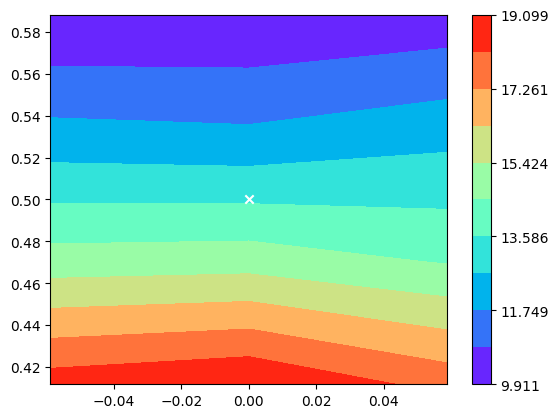

In [8]:
fig0, ax0 = plt.subplots()
Xv, Yv = np.meshgrid(Xm, Ym, indexing='ij')
contour0 = ax0.contourf(Xv, Yv, energym, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

#region = patches.Rectangle((x0, y0), roi_side, roi_side, linewidth=1, edgecolor='r', facecolor='none')
#ax0.add_patch(region)
ax0.scatter(roi_cm[0], roi_cm[1], color="white", marker="x")

cbar0 = fig0.colorbar(contour0)

### Linear plots

In [17]:
# Extract energy along theta = pi/2
theta = pi/2
error = 0.05 # cm

lin_mosh, const_rad_mosh = energy_along_theta(mosh, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, err=error, 
                                              radius=applicator_rad + 0.05, scale=True, norm_energy=norm_energy, dose=dose)

#print(lin_mosh)

# Extract arrays to plot dose
xm, ym, std_dev_sum_m, std_dev_mean_m, __ = plotter_1D(lin_mosh, plot_rng=(0.3, 1.0), std_dev=False, num_Hx=1e7)

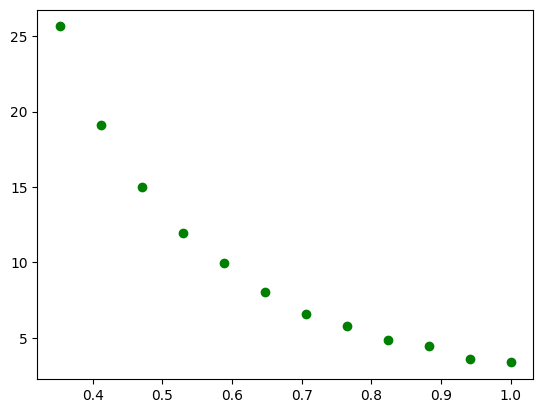

In [10]:
fig1, ax1 = plt.subplots()
ax1.scatter(xm, ym, color="g")

In [11]:
# Debugging energy shift observed above
voxels = np.array([50, 42])
cm = voxel_to_cm(voxels, bins_mosh, lattice_mosh)
print(cm)

[0.47058824 0.        ]


In [12]:
cart_plane = np.array([[cm[0], cm[1], 2e1], [cm[0], cm[1], 2e1]])
polar_plane = cart_to_polar(cart_plane)
print(polar_plane)

[[ 0.47058824  0.         20.        ]
 [ 0.47058824  0.         20.        ]]


In [13]:
polar_plane[:, 1:]

array([[ 0., 20.],
       [ 0., 20.]])

In [14]:
print(np.arctan2(0, 0.5))
print(np.arctan2(0.5, 0))

0.0
1.5707963267948966
